# 05 · Explicabilidad con SHAP
¿Qué variables mueven las predicciones? Usamos SHAP (TreeExplainer) sobre los modelos finales.

**SHAP** reparte cada predicción entre las variables: el valor SHAP de una variable es cuánto empujó esa predicción hacia arriba (+) o hacia abajo (−) respecto de la predicción promedio del modelo.

**Contenido:** 1) importancia global · 2) beeswarm (dirección del efecto) · 3) dependencia · 4) explicación de una predicción individual · 5) pozo nuevo · reflexión y conclusiones.

> **Qué hace esta celda:** importa las librerías, carga la configuración del proyecto (rutas y umbrales de `src/ypf_ds/config.py`) y define el estilo de los gráficos.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, polars as pl, duckdb
import matplotlib.pyplot as plt, seaborn as sns
from ypf_ds import config
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.figsize"] = (11, 4.5)
config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

> **Qué hace esta celda:** carga SHAP y define una función que toma una muestra del período de test (horizontes 1, 6 y 12) con las mismas columnas y categorías que usa el modelo final.

In [2]:
import joblib, shap
from ypf_ds.features import build as fb
panel, pozos = pl.read_parquet(config.PANEL), pl.read_parquet(config.POZOS)
def muestra_a(fluido, n=4000):
    art = joblib.load(config.DIR_MODELOS / f"{fluido}_existente.joblib")
    df = fb.dataset_modo_a(panel, pozos, fluido, horizontes=[1, 6, 12])
    df = df.filter(pl.Series(fb.particion_temporal(df["fecha_obj"]) == "test")).sample(n, seed=42)
    X, _ = fb.a_pandas(df, art["columnas"], art["categoricas"], art["categorias"])
    return art, X, df

> **Qué hace esta celda:** calcula los valores SHAP del modelo de pozo existente para petróleo y gas (en unidades del ratio respecto del último mes).

In [3]:
shap_a = {}
for fluido in ["petroleo", "gas"]:
    art, X, df = muestra_a(fluido)
    explainer = shap.TreeExplainer(art["modelos"]["p50"])
    shap_a[fluido] = (explainer(X), X, df)
print("Valores SHAP calculados:", {k: v[0].values.shape for k, v in shap_a.items()})

Valores SHAP calculados: {'petroleo': (4000, 53), 'gas': (4000, 53)}


## 1. Importancia global

> **Qué hace esta celda:** grafica la importancia global: el promedio del valor absoluto SHAP de cada variable (cuánto mueve la predicción en promedio, sin importar el sentido).

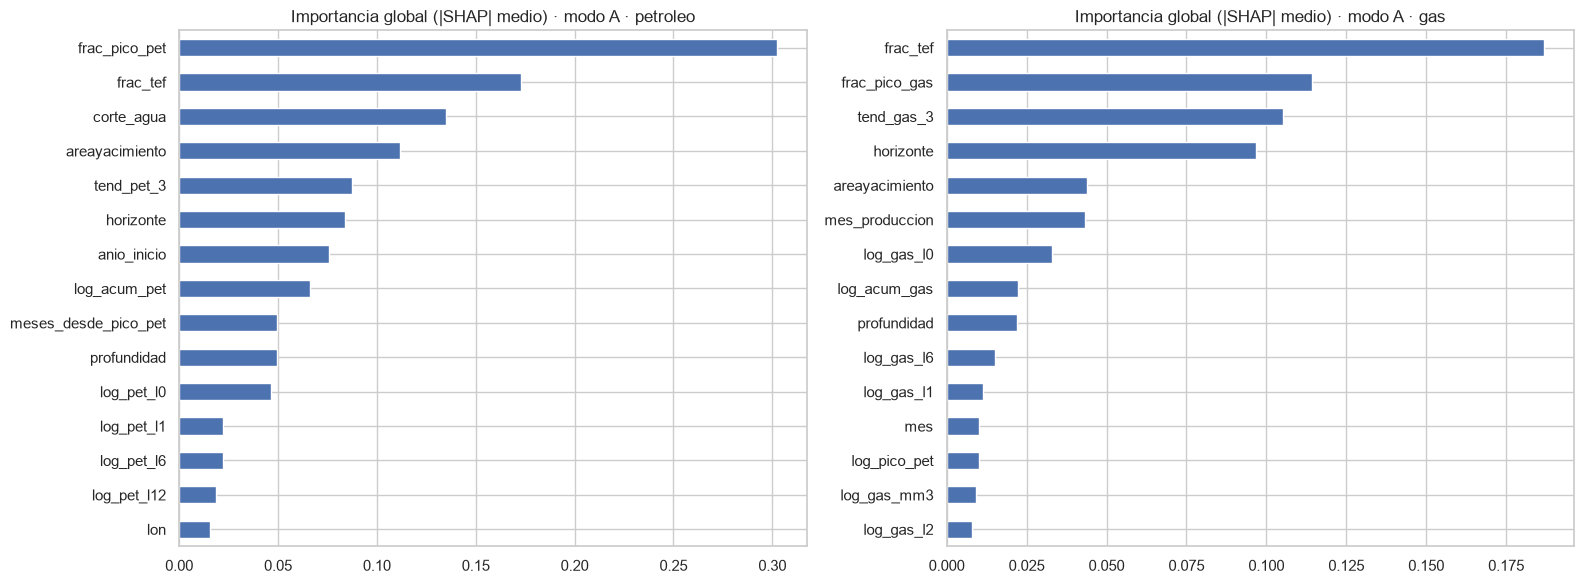

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, fluido in zip(ax, shap_a):
    sv, X, _ = shap_a[fluido]
    imp = pd.Series(np.abs(sv.values).mean(0), index=X.columns).sort_values().tail(15)
    imp.plot.barh(ax=a, color="C0"); a.set_title(f"Importancia global (|SHAP| medio) · modo A · {fluido}")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "05_shap_importancia.png", dpi=110); plt.show()

## 2. Beeswarm: dirección del efecto
Cada punto es una predicción. El color indica el valor de la variable (rojo = alto, azul = bajo) y la posición horizontal su efecto sobre la predicción.

> **Qué hace esta celda:** dibuja el gráfico beeswarm de SHAP para petróleo y gas.

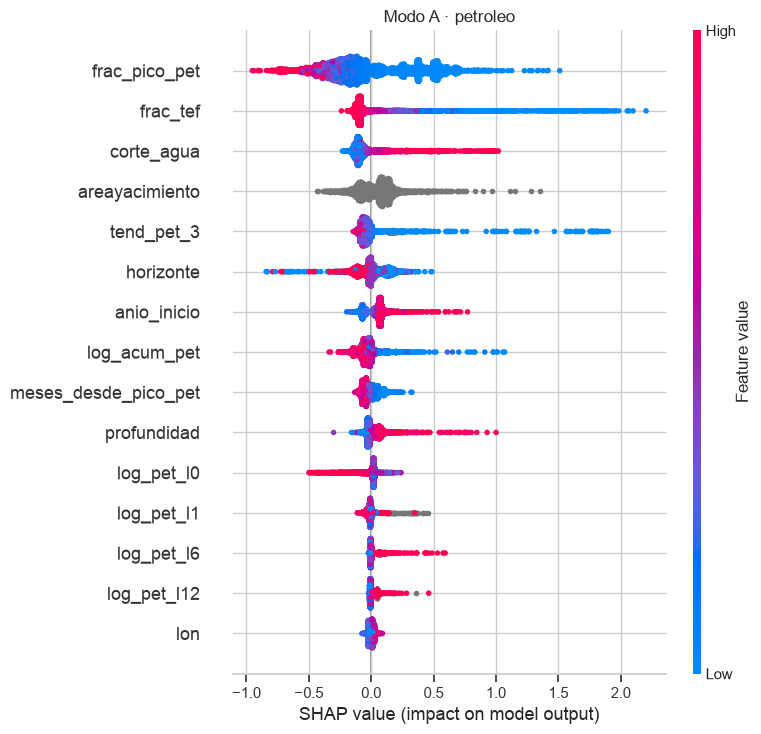

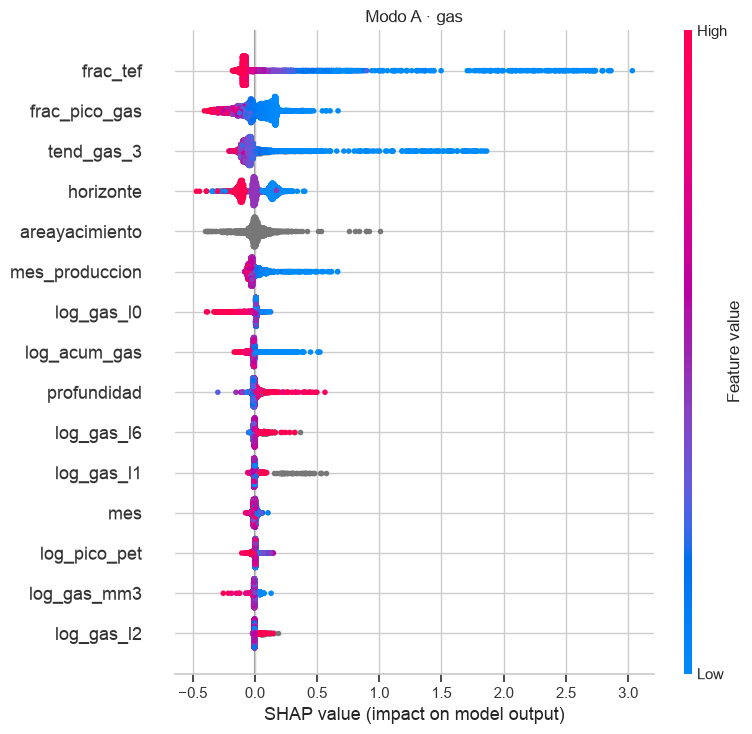

In [5]:
for fluido in shap_a:
    sv, X, _ = shap_a[fluido]
    plt.figure(); shap.summary_plot(sv.values, X, max_display=15, show=False)
    plt.title(f"Modo A · {fluido}"); plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / f"05_shap_A_{fluido}.png", dpi=110); plt.show()

En el modo A dominan la **posición respecto del pico** (`frac_pico`: un pozo en su pico solo puede bajar), la **fracción de días producidos** (`frac_tef`: si el último mes fue parcial por una parada, el modelo espera una recuperación), la **tendencia reciente** y el **horizonte** (más lejos → menor ratio). En petróleo pesan además el **corte de agua** y el **yacimiento**. El modelo aprendió la física de la declinación y el efecto de las paradas.

## 3. Dependencia

> **Qué hace esta celda:** grafica cómo cambia el efecto SHAP según el valor de las dos variables más importantes (gráfico de dependencia), coloreado por la variable con la que más interactúa. Las variables categóricas se muestran con su código numérico.

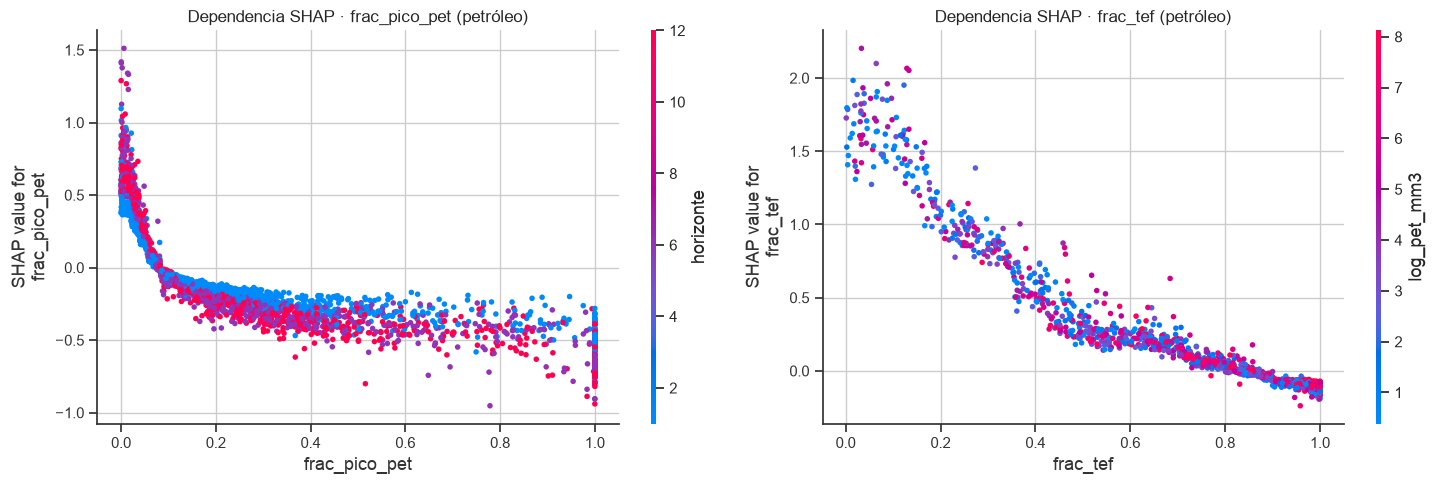

In [6]:
sv, X, _ = shap_a["petroleo"]
top2 = pd.Series(np.abs(sv.values).mean(0), index=X.columns).sort_values(ascending=False).index[:2]
# SHAP necesita números para buscar interacciones: las categóricas se grafican con su código
Xnum = X.apply(lambda s: s.cat.codes if s.dtype == "category" else s)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, var in zip(ax, top2):
    shap.dependence_plot(var, sv.values, Xnum, ax=a, show=False)
    a.set_title(f"Dependencia SHAP · {var} (petróleo)")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "05_shap_dependencia.png", dpi=110); plt.show()

Los gráficos de dependencia muestran relaciones **no lineales** que un modelo lineal no podría capturar: el efecto cambia de pendiente según la etapa del pozo.

## 4. Explicación de una predicción individual

> **Qué hace esta celda:** elige una predicción a 12 meses de un pozo de Vaca Muerta y la descompone con un gráfico *waterfall*: parte del valor promedio del modelo y suma el aporte de cada variable hasta llegar a la predicción.

Pozo 158365 · último mes 384 m³ · real a 12 meses 408 m³
Ratio predicho: 0.693 → 266 m³


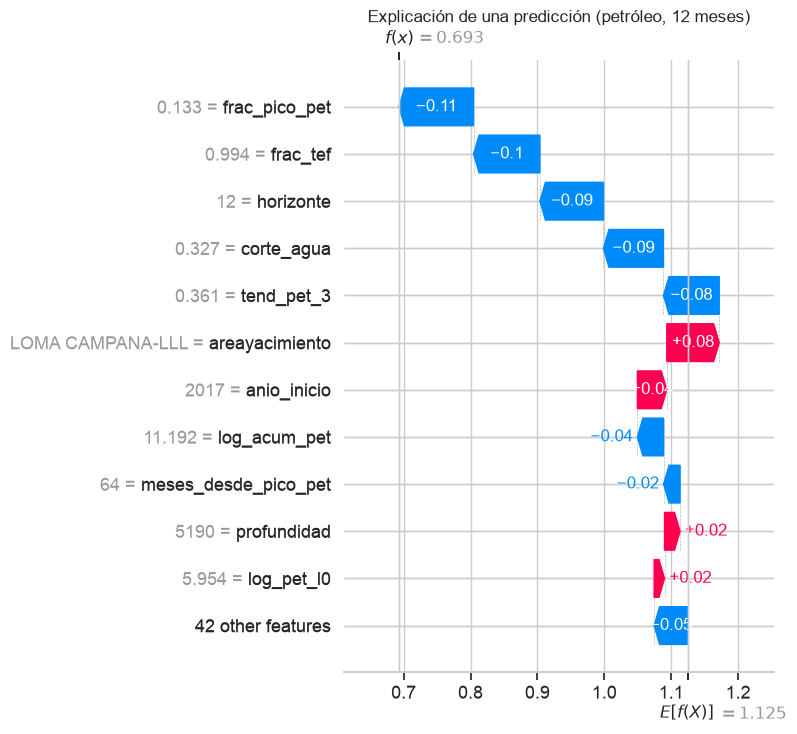

In [7]:
sv, X, df = shap_a["petroleo"]
i = int(np.flatnonzero((df["horizonte"].to_numpy() == 12) & (df["formacion"].to_numpy() == "vaca muerta"))[0])
fila = df.row(i, named=True)
print(f"Pozo {fila['idpozo']} · último mes {fila['prod_origen']:.0f} m³ · real a 12 meses {fila['prod_obj']:.0f} m³")
print(f"Ratio predicho: {sv.base_values[i] + sv.values[i].sum():.3f} → {fila['prod_origen'] * (sv.base_values[i] + sv.values[i].sum()):.0f} m³")
shap.plots.waterfall(sv[i], max_display=12, show=False)
plt.title("Explicación de una predicción (petróleo, 12 meses)"); plt.tight_layout()
plt.savefig(config.DIR_FIGURAS / "05_shap_waterfall.png", dpi=110, bbox_inches="tight"); plt.show()

El *waterfall* es lo que la API resume en la tabla **"Qué explica la predicción"** del frontend: las variables que más subieron o bajaron el pronóstico de ese pozo.

## 5. Modo B — pozo nuevo

> **Qué hace esta celda:** calcula y grafica SHAP para los modelos de pozo nuevo (petróleo en m³/mes; gas en escala log porque usa un objetivo Tweedie).

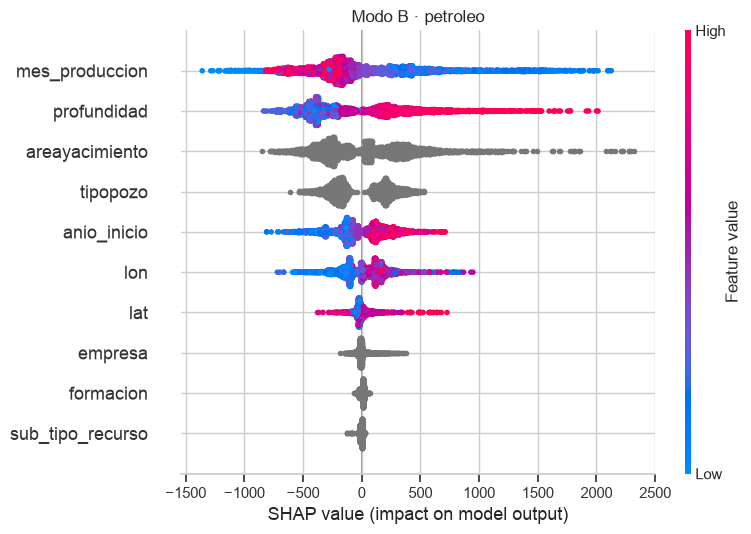

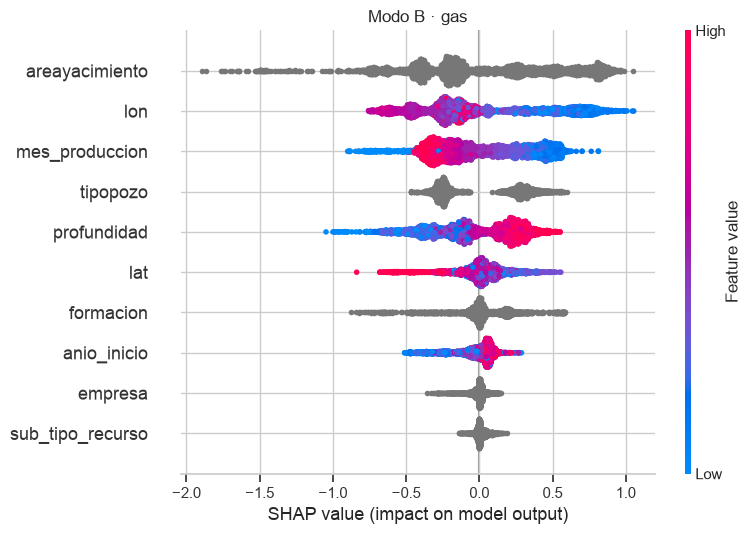

In [8]:
for fluido in ["petroleo", "gas"]:
    art = joblib.load(config.DIR_MODELOS / f"{fluido}_nuevo.joblib")
    df = fb.dataset_modo_b(panel, pozos, fluido).sample(4000, seed=42)
    X, _ = fb.a_pandas(df, art["columnas"], art["categoricas"], art["categorias"])
    sv_b = shap.TreeExplainer(art["modelos"]["p50"]).shap_values(X)
    plt.figure(); shap.summary_plot(sv_b, X, show=False)
    plt.title(f"Modo B · {fluido}"); plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / f"05_shap_B_{fluido}.png", dpi=110); plt.show()

En el modo B (pozo nuevo) pesan la **profundidad** (en pozos horizontales incluye la rama lateral), el **mes de vida** (la forma de la curva), el **yacimiento**, la **ubicación**, el **tipo de pozo declarado** y el **año de inicio**: los pozos más recientes tienen ramas más largas y más etapas de fractura, lo que se ve como una tendencia creciente de productividad por año.

### Reflexión: sesgos y límites
- **Sesgo de representación:** Vaca Muerta y YPF concentran la mayoría de los datos; para formaciones u operadoras con pocos pozos la predicción es menos confiable.
- **Variables omitidas:** el dataset no tiene longitud de rama lateral, número de etapas ni volumen de agente de sostén, que son los principales determinantes de productividad. El año de inicio y la profundidad actúan como *proxies* imperfectos.
- **Correlación no es causalidad:** SHAP explica qué usa el **modelo**, no qué causa la producción. Por ejemplo, la profundidad "suma" porque se asocia a pozos horizontales modernos, no porque perforar más hondo produzca más por sí mismo.
- **Drift:** la tecnología de completación mejora año a año; un pozo de 2027 probablemente rinda más de lo que el modelo predice. Hay que reentrenar periódicamente.
- **Uso responsable:** la predicción es orientativa, no reemplaza un estudio de reservorio ni debe usarse sola para decisiones de inversión.

## Conclusiones de la explicabilidad
1. **Pozo existente:** el modelo se apoya en variables con sentido físico (posición respecto del pico, días producidos, tendencia, horizonte, corte de agua), no en atajos: es una señal de que **no hay fuga de datos**.
2. **Relaciones no lineales:** los gráficos de dependencia muestran efectos que cambian según la etapa del pozo; esto explica por qué los árboles superan a Ridge.
3. **Pozo nuevo:** la productividad depende de la ubicación, la profundidad (rama lateral), el tipo de pozo y el año (tecnología).
4. **Transparencia en el producto:** cada predicción de la API incluye su descomposición SHAP, igual que el *waterfall* de este notebook.
5. **Límites:** SHAP explica el modelo, no la física del reservorio; las conclusiones causales requieren conocimiento de ingeniería.